# Практическое занятие 1
## Свёртка, матрица Тёплица и простейшие фильтры

Курс: **Дискретный вейвлет-анализ и банки фильтров**.

В notebook используются только `numpy` и `matplotlib`.

План:
1. полная свёртка вручную;
2. матричная форма свёртки — матрица Тёплица;
3. собственная реализация `conv_full`;
4. частотные характеристики $H_0(\omega)$ и $H_1(\omega)$;
5. фильтрация сигнала из двух гармоник;
6. выходной мини-тест и выводы.

В приложении те же задания повторены в программе Signals.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=4, suppress=True)

### Исходные данные

Нумерация отсчётов начинается с нуля:

$x=[2,-1,3,1]$, $\quad h_0=[1/2,\ 1/2]$, $\quad h_1=[1/2,\ -1/2]$.

In [2]:
x = np.array([2, -1, 3, 1], dtype=float)
h0 = np.array([0.5, 0.5])
h1 = np.array([0.5, -0.5])

## Задание 1. Полная свёртка вручную

Полная линейная свёртка: $\;y[n]=(x*h)[n]=\sum_k x[k]\,h[n-k]$.

Обе последовательности ненулевые на индексах $x:\ 0..3$, $h:\ 0..1$, поэтому $y$ ненулевая на $n=0..3+1=0..4$, а длина равна $N_y=N_x+N_h-1=4+2-1=5$.

**1. $y_0=x*h_0$**, где $h_0[0]=h_0[1]=\tfrac12$, то есть $y_0[n]=\tfrac12x[n]+\tfrac12x[n-1]$:

| $n$ | слагаемые | $y_0[n]$ |
|---|---|---|
| 0 | $x[0]h_0[0]=2\cdot\tfrac12$ | $1$ |
| 1 | $x[0]h_0[1]+x[1]h_0[0]=1-\tfrac12$ | $0.5$ |
| 2 | $x[1]h_0[1]+x[2]h_0[0]=-\tfrac12+\tfrac32$ | $1$ |
| 3 | $x[2]h_0[1]+x[3]h_0[0]=\tfrac32+\tfrac12$ | $2$ |
| 4 | $x[3]h_0[1]=\tfrac12$ | $0.5$ |

$$y_0=[1,\ 0.5,\ 1,\ 2,\ 0.5].$$

**2. $y_1=x*h_1$**, где $h_1[0]=\tfrac12$, $h_1[1]=-\tfrac12$, то есть $y_1[n]=\tfrac12x[n]-\tfrac12x[n-1]$:

| $n$ | слагаемые | $y_1[n]$ |
|---|---|---|
| 0 | $x[0]h_1[0]=2\cdot\tfrac12$ | $1$ |
| 1 | $x[0]h_1[1]+x[1]h_1[0]=-1-\tfrac12$ | $-1.5$ |
| 2 | $x[1]h_1[1]+x[2]h_1[0]=\tfrac12+\tfrac32$ | $2$ |
| 3 | $x[2]h_1[1]+x[3]h_1[0]=-\tfrac32+\tfrac12$ | $-1$ |
| 4 | $x[3]h_1[1]=-\tfrac12$ | $-0.5$ |

$$y_1=[1,\ -1.5,\ 2,\ -1,\ -0.5].$$

**3. Длина и индексы.** Оба результата имеют длину $5$ и диапазон индексов $n=0,1,2,3,4$.

**4. Чем различаются $h_0$ и $h_1$.** $h_0$ — локальное среднее двух соседних отсчётов: медленные изменения сохраняются, быстрые сглаживаются, постоянный сигнал проходит без изменения. $h_1$ — локальная полуразность: отклик тем больше, чем сильнее соседние отсчёты отличаются друг от друга, а постоянный сигнал даёт ноль. Вместе они раскладывают сигнал на «среднее» и «перепад»: $h_0+h_1=[1,0]=\delta$, поэтому $y_0[n]+y_1[n]=x[n]$.

Проверим ручной расчёт (здесь `np.convolve` используется только как независимая проверка):

In [3]:
y0_manual = np.array([1, 0.5, 1, 2, 0.5])
y1_manual = np.array([1, -1.5, 2, -1, -0.5])

print("y0 вручную:", y0_manual, "| np.convolve:", np.convolve(x, h0))
print("y1 вручную:", y1_manual, "| np.convolve:", np.convolve(x, h1))
assert np.allclose(y0_manual, np.convolve(x, h0))
assert np.allclose(y1_manual, np.convolve(x, h1))

print("длины:", len(y0_manual), len(y1_manual), "= len(x) + len(h) - 1 =", len(x) + len(h0) - 1)
print("индексы n:", np.arange(len(y0_manual)))
print("y0 + y1 =", y0_manual + y1_manual, " — это x, дополненный нулём:", np.append(x, 0))

y0 вручную: [1.  0.5 1.  2.  0.5] | np.convolve: [1.  0.5 1.  2.  0.5]
y1 вручную: [ 1.  -1.5  2.  -1.  -0.5] | np.convolve: [ 1.  -1.5  2.  -1.  -0.5]
длины: 5 5 = len(x) + len(h) - 1 = 5
индексы n: [0 1 2 3 4]
y0 + y1 = [ 2. -1.  3.  1.  0.]  — это x, дополненный нулём: [ 2. -1.  3.  1.  0.]


## Задание 2. Матричная форма

Свёртку конечных последовательностей можно записать как умножение на матрицу: $y=Hx$, где $H[n,k]=h[n-k]$ (и $0$, если $n-k$ вне $0..N_h-1$).

Каждый столбец — копия $h$, сдвинутая на один отсчёт вниз. Значит, элемент зависит только от разности $n-k$, и матрица постоянна вдоль диагоналей, то есть является тёплицевой. Для $N_x=4$, $N_h=2$ размер матрицы $(N_x+N_h-1)\times N_x=5\times4$.

In [4]:
def convolution_matrix(h: np.ndarray, input_length: int) -> np.ndarray:
    # Матрица Тёплица полной свёртки: H[n, k] = h[n - k]
    h = np.asarray(h, dtype=float)
    if h.ndim != 1 or h.size == 0:
        raise ValueError("h должен быть непустым одномерным массивом")
    if input_length <= 0:
        raise ValueError("длина входа должна быть положительной")
    H = np.zeros((input_length + h.size - 1, input_length))
    for k in range(input_length):
        H[k:k + h.size, k] = h
    return H


def is_toeplitz(H: np.ndarray) -> bool:
    # Каждая диагональ (смещение d) должна состоять из одного значения
    rows, cols = H.shape
    return all(np.allclose(np.diag(H, d), np.diag(H, d)[0]) for d in range(-(rows - 1), cols))


H0 = convolution_matrix(h0, len(x))
H1 = convolution_matrix(h1, len(x))

print("H0 =\n", H0, "\n")
print("H1 =\n", H1, "\n")
print("H0 @ x =", H0 @ x, "| y0 =", y0_manual)
print("H1 @ x =", H1 @ x, "| y1 =", y1_manual)
assert np.allclose(H0 @ x, y0_manual) and np.allclose(H1 @ x, y1_manual)

for name, H in (("H0", H0), ("H1", H1)):
    print(f"{name}: размер {H.shape}, тёплицева: {is_toeplitz(H)}")
    for d in range(-1, 1):
        print(f"   диагональ со смещением {d:+d}: {np.diag(H, d)}")

H0 =
 [[0.5 0.  0.  0. ]
 [0.5 0.5 0.  0. ]
 [0.  0.5 0.5 0. ]
 [0.  0.  0.5 0.5]
 [0.  0.  0.  0.5]] 

H1 =
 [[ 0.5  0.   0.   0. ]
 [-0.5  0.5  0.   0. ]
 [ 0.  -0.5  0.5  0. ]
 [ 0.   0.  -0.5  0.5]
 [ 0.   0.   0.  -0.5]] 

H0 @ x = [1.  0.5 1.  2.  0.5] | y0 = [1.  0.5 1.  2.  0.5]
H1 @ x = [ 1.  -1.5  2.  -1.  -0.5] | y1 = [ 1.  -1.5  2.  -1.  -0.5]
H0: размер (5, 4), тёплицева: True
   диагональ со смещением -1: [0.5 0.5 0.5 0.5]
   диагональ со смещением +0: [0.5 0.5 0.5 0.5]
H1: размер (5, 4), тёплицева: True
   диагональ со смещением -1: [-0.5 -0.5 -0.5 -0.5]
   диагональ со смещением +0: [0.5 0.5 0.5 0.5]


Главная диагональ $H_0$ состоит из $h_0[0]=\tfrac12$, поддиагональ — из $h_0[1]=\tfrac12$, остальные диагонали нулевые. У $H_1$ на главной диагонали $\tfrac12$, на поддиагонали $-\tfrac12$. Элементы постоянны вдоль каждой диагонали, что и проверила функция `is_toeplitz`.

## Задание 3. Собственная реализация свёртки

Функция считает сумму $y[n]=\sum_k x[k]\,h[n-k]$ двумя вложенными циклами. Индекс $k$ пробегает только те значения, при которых оба множителя существуют: $0\le k\le N_x-1$ и $0\le n-k\le N_h-1$.

In [5]:
def conv_full(x: np.ndarray, h: np.ndarray) -> np.ndarray:
    """Полная линейная свёртка двух одномерных массивов."""
    x = np.asarray(x, dtype=float)
    h = np.asarray(h, dtype=float)
    if x.ndim != 1 or h.ndim != 1:
        raise ValueError("входы должны быть одномерными массивами")
    if x.size == 0 or h.size == 0:
        raise ValueError("входы не должны быть пустыми")
    nx, nh = x.size, h.size
    y = np.zeros(nx + nh - 1)
    for n in range(nx + nh - 1):
        for k in range(max(0, n - nh + 1), min(n, nx - 1) + 1):
            y[n] += x[k] * h[n - k]
    return y


print("conv_full(x, h0) =", conv_full(x, h0))
print("conv_full(x, h1) =", conv_full(x, h1))

conv_full(x, h0) = [1.  0.5 1.  2.  0.5]
conv_full(x, h1) = [ 1.  -1.5  2.  -1.  -0.5]


Проверка: совпадение с `np.convolve(x, h, mode="full")` на данных задания и на случайных массивах разной длины, включая массивы из одного отсчёта, а также отказ на неверных входах.

In [6]:
assert np.allclose(conv_full(x, h0), np.convolve(x, h0, mode="full"))
assert np.allclose(conv_full(x, h1), np.convolve(x, h1, mode="full"))

rng = np.random.default_rng(0)
worst = 0.0
for nx, nh in [(1, 1), (1, 5), (5, 1), (4, 2), (7, 3), (16, 9), (50, 50), (128, 2)]:
    a, b = rng.standard_normal(nx), rng.standard_normal(nh)
    ours, ref = conv_full(a, b), np.convolve(a, b, mode="full")
    assert ours.shape == ref.shape
    worst = max(worst, np.max(np.abs(ours - ref)))
print(f"максимальное расхождение с np.convolve на случайных тестах: {worst:.2e}")

for bad in (np.array([]), np.ones((2, 2))):
    try:
        conv_full(bad, h0)
    except ValueError as e:
        print(f"вход формы {bad.shape} отклонён: {e}")

максимальное расхождение с np.convolve на случайных тестах: 5.33e-15
вход формы (0,) отклонён: входы не должны быть пустыми
вход формы (2, 2) отклонён: входы должны быть одномерными массивами


## Задание 4. Частотные характеристики

$$H(\omega)=\sum_k h[k]\,e^{-i\omega k}.$$

Для двухточечных фильтров:

$$H_0(\omega)=\tfrac12+\tfrac12e^{-i\omega}=e^{-i\omega/2}\cos\tfrac{\omega}{2},\qquad |H_0(\omega)|=\left|\cos\tfrac{\omega}{2}\right|,$$

$$H_1(\omega)=\tfrac12-\tfrac12e^{-i\omega}=i\,e^{-i\omega/2}\sin\tfrac{\omega}{2},\qquad |H_1(\omega)|=\left|\sin\tfrac{\omega}{2}\right|.$$

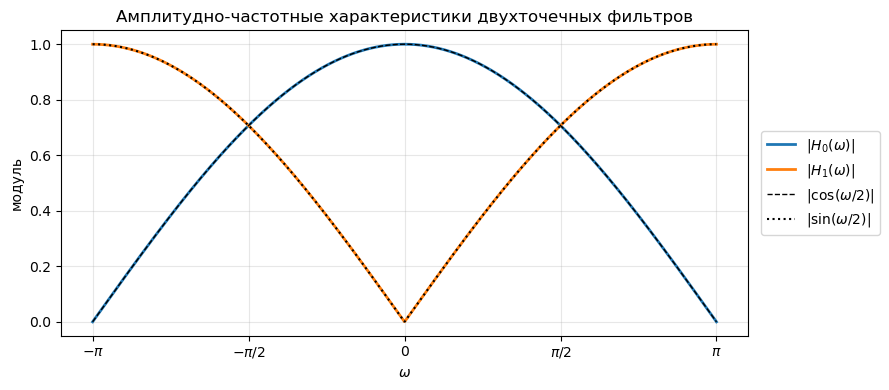

In [7]:
def freq_response(h: np.ndarray, omega: np.ndarray) -> np.ndarray:
    # DTFT конечной импульсной характеристики: H(w) = sum_k h[k] exp(-i w k)
    h = np.asarray(h, dtype=float)
    k = np.arange(h.size)
    return np.exp(-1j * np.outer(omega, k)) @ h


omega = np.linspace(-np.pi, np.pi, 1200)
FH0 = freq_response(h0, omega)
FH1 = freq_response(h1, omega)

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(omega, np.abs(FH0), lw=2, label=r"$|H_0(\omega)|$")
ax.plot(omega, np.abs(FH1), lw=2, label=r"$|H_1(\omega)|$")
ax.plot(omega, np.abs(np.cos(omega / 2)), "k--", lw=1, label=r"$|\cos(\omega/2)|$")
ax.plot(omega, np.abs(np.sin(omega / 2)), "k:", lw=1.5, label=r"$|\sin(\omega/2)|$")
ax.set_xticks([-np.pi, -np.pi / 2, 0, np.pi / 2, np.pi])
ax.set_xticklabels([r"$-\pi$", r"$-\pi/2$", "0", r"$\pi/2$", r"$\pi$"])
ax.set_xlabel(r"$\omega$")
ax.set_ylabel("модуль")
ax.set_title("Амплитудно-частотные характеристики двухточечных фильтров")
ax.grid(alpha=0.3)
ax.legend(loc="center left", bbox_to_anchor=(1.01, 0.5))
plt.tight_layout()
plt.show()

**1. Значения при $\omega=0$ и $\omega=\pi$.**

In [8]:
check = np.array([0.0, np.pi])
for name, h in (("H0", h0), ("H1", h1)):
    v = freq_response(h, check)
    print(f"{name}(0) = {v[0]:.4f},  {name}(pi) = {v[1]:.4f}   |{name}(0)| = {abs(v[0]):.4f}, |{name}(pi)| = {abs(v[1]):.4f}")

H0(0) = 1.0000+0.0000j,  H0(pi) = 0.0000-0.0000j   |H0(0)| = 1.0000, |H0(pi)| = 0.0000
H1(0) = 0.0000+0.0000j,  H1(pi) = 1.0000+0.0000j   |H1(0)| = 0.0000, |H1(pi)| = 1.0000


$H_0(0)=1$, $H_0(\pi)=0$; $H_1(0)=0$, $|H_1(\pi)|=1$. Ноль на месте $H_0(\pi)$ и $H_1(0)$ появляется с точностью до округления, около $10^{-17}$.

**2. Сравнение с $|\cos(\omega/2)|$ и $|\sin(\omega/2)|$.** Графики совпадают с формулами: штриховые линии лежат на кривых. Численное расхождение по всей сетке:

In [9]:
err0 = np.max(np.abs(np.abs(FH0) - np.abs(np.cos(omega / 2))))
err1 = np.max(np.abs(np.abs(FH1) - np.abs(np.sin(omega / 2))))
print(f"max | |H0| - |cos(w/2)| | = {err0:.2e}")
print(f"max | |H1| - |sin(w/2)| | = {err1:.2e}")
print(f"max | |H0|^2 + |H1|^2 - 1 | = {np.max(np.abs(np.abs(FH0) ** 2 + np.abs(FH1) ** 2 - 1)):.2e}")

max | |H0| - |cos(w/2)| | = 2.22e-16
max | |H1| - |sin(w/2)| | = 2.22e-16
max | |H0|^2 + |H1|^2 - 1 | = 4.44e-16


**3. ФНЧ и ФВЧ.** $h_0$ — фильтр нижних частот: на $\omega=0$ его модуль равен $1$, к $\omega=\pm\pi$ он спадает до нуля. $h_1$ — фильтр верхних частот: он подавляет $\omega=0$, то есть постоянную составляющую, и пропускает без ослабления $\omega=\pm\pi$, то есть чередующуюся последовательность $(-1)^n$.

Кроме того, $|H_0|^2+|H_1|^2=\cos^2\tfrac\omega2+\sin^2\tfrac\omega2=1$: пара делит энергию сигнала между двумя полосами без потерь. Нормированная пара станет банком Хаара.

## Задание 5. Фильтрация сигнала из двух гармоник

$$x[n]=\sin(0.15\pi n)+0.35\sin(0.80\pi n),\qquad n=0,\dots,127.$$

Низкая гармоника $\omega_1=0.15\pi$ лежит в полосе пропускания $h_0$, а высокая $\omega_2=0.80\pi$ ближе к полосе $h_1$.

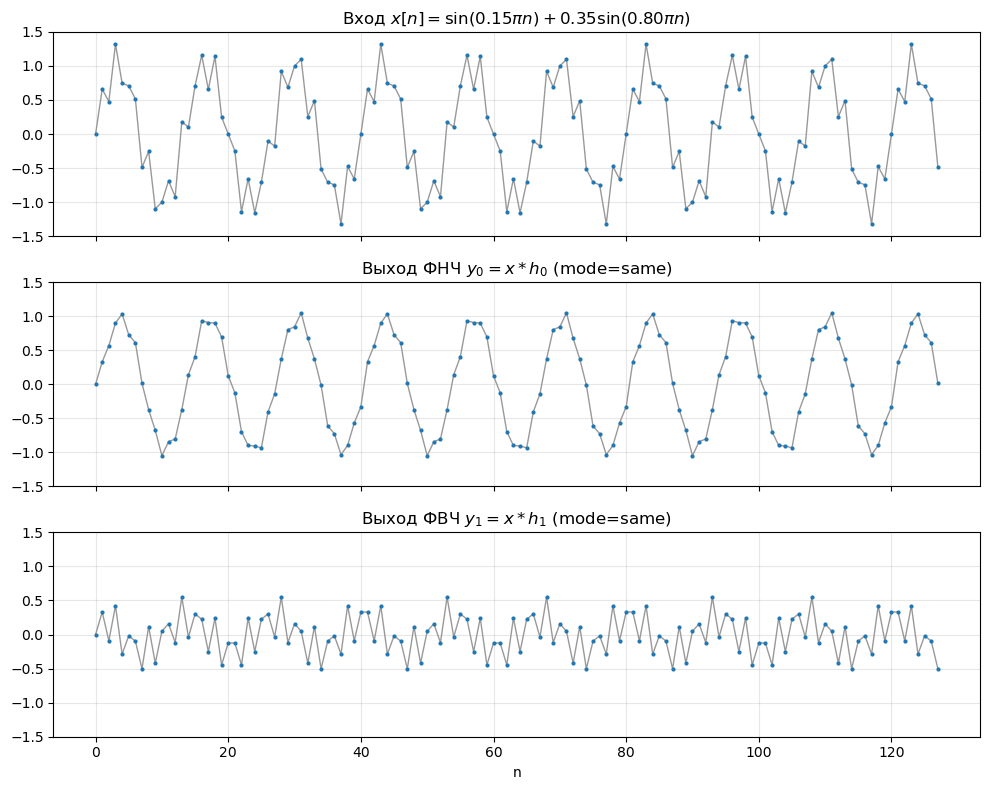

In [10]:
n = np.arange(128)
w1, w2 = 0.15 * np.pi, 0.80 * np.pi
x_mix = np.sin(w1 * n) + 0.35 * np.sin(w2 * n)

y0_mix = np.convolve(x_mix, h0, mode="same")
y1_mix = np.convolve(x_mix, h1, mode="same")

# Для фильтра из двух отводов режим same — это первые len(x) отсчётов полной свёртки
assert np.allclose(y0_mix, conv_full(x_mix, h0)[:len(x_mix)])
assert np.allclose(y1_mix, conv_full(x_mix, h1)[:len(x_mix)])

fig, axes = plt.subplots(3, 1, figsize=(10, 8), sharex=True)
for ax, sig, title in zip(axes,
                          (x_mix, y0_mix, y1_mix),
                          (r"Вход $x[n]=\sin(0.15\pi n)+0.35\sin(0.80\pi n)$",
                           r"Выход ФНЧ $y_0=x*h_0$ (mode=same)",
                           r"Выход ФВЧ $y_1=x*h_1$ (mode=same)")):
    ax.plot(n, sig, "-", lw=1, color="0.6")
    ax.plot(n, sig, ".", ms=4)
    ax.set_title(title)
    ax.set_ylim(-1.5, 1.5)
    ax.grid(alpha=0.3)
axes[-1].set_xlabel("n")
plt.tight_layout()
plt.show()

**3. Объяснение через $|H(\omega)|$.** Каждая гармоника проходит через фильтр с той же частотой. Её амплитуда умножается на $|H(\omega)|$, фаза сдвигается на $\arg H(\omega)$.

In [11]:
gains = {
    "|H0(0.15pi)|": abs(freq_response(h0, np.array([w1]))[0]),
    "|H0(0.80pi)|": abs(freq_response(h0, np.array([w2]))[0]),
    "|H1(0.15pi)|": abs(freq_response(h1, np.array([w1]))[0]),
    "|H1(0.80pi)|": abs(freq_response(h1, np.array([w2]))[0]),
}
for k, v in gains.items():
    print(f"{k} = {v:.4f}")
print(f"для сравнения: cos(0.075pi) = {np.cos(0.075 * np.pi):.4f}, cos(0.4pi) = {np.cos(0.4 * np.pi):.4f}, "
      f"sin(0.075pi) = {np.sin(0.075 * np.pi):.4f}, sin(0.4pi) = {np.sin(0.4 * np.pi):.4f}")


def amplitudes(sig, start=1):
    # Амплитуды двух гармоник на выходе: наименьшие квадраты по sin и cos каждой частоты
    m = n[start:]
    basis = np.column_stack([np.sin(w1 * m), np.cos(w1 * m), np.sin(w2 * m), np.cos(w2 * m)])
    c, *_ = np.linalg.lstsq(basis, sig[start:], rcond=None)
    return np.hypot(c[0], c[1]), np.hypot(c[2], c[3])


print()
print(f"{'':10s}{'гармоника 0.15pi':>20s}{'гармоника 0.80pi':>20s}")
print(f"{'вход':10s}{1.0:>20.4f}{0.35:>20.4f}")
for name, sig, g1, g2 in (("выход h0", y0_mix, gains['|H0(0.15pi)|'], gains['|H0(0.80pi)|']),
                          ("выход h1", y1_mix, gains['|H1(0.15pi)|'], gains['|H1(0.80pi)|'])):
    a1, a2 = amplitudes(sig)
    print(f"{name:10s}{a1:>11.4f} (теория {1.0 * g1:.4f}){a2:>9.4f} (теория {0.35 * g2:.4f})")

|H0(0.15pi)| = 0.9724
|H0(0.80pi)| = 0.3090
|H1(0.15pi)| = 0.2334
|H1(0.80pi)| = 0.9511
для сравнения: cos(0.075pi) = 0.9724, cos(0.4pi) = 0.3090, sin(0.075pi) = 0.2334, sin(0.4pi) = 0.9511

              гармоника 0.15pi    гармоника 0.80pi
вход                    1.0000              0.3500
выход h0       0.9724 (теория 0.9724)   0.1082 (теория 0.1082)
выход h1       0.2334 (теория 0.2334)   0.3329 (теория 0.3329)


ФНЧ $h_0$ почти не меняет низкую гармонику: $|H_0(0.15\pi)|=\cos(0.075\pi)\approx0.972$. Высокую он ослабляет втрое: $|H_0(0.80\pi)|=\cos(0.4\pi)\approx0.309$, её амплитуда падает с $0.35$ до $\approx0.108$. Поэтому на графике $y_0$ видна почти чистая медленная синусоида с небольшой рябью.

ФВЧ $h_1$ подавляет низкую гармонику: $|H_1(0.15\pi)|=\sin(0.075\pi)\approx0.233$. Высокая проходит почти целиком: $|H_1(0.80\pi)|=\sin(0.4\pi)\approx0.951$, амплитуда $\approx0.333$. В $y_1$ обе составляющие сравнимы ($0.233$ и $0.333$), хотя быстрая уже преобладает. Это и есть «неидеальное разделение» из лекции: у двухточечных фильтров очень широкая переходная полоса.

Амплитуды, измеренные на выходе методом наименьших квадратов, совпадают с теорией $|H(\omega)|\cdot A$.

**4. Граничные искажения при `mode="same"`.** Режим `same` возвращает $N=128$ отсчётов полной свёртки длины $N+1$. Для фильтра из двух отводов это отсчёты $0..127$.

- На левой границе `np.convolve` считает, что до начала сигнала стоят нули ($x[-1]=0$). Поэтому $y[0]=h[0]x[0]$ — это неполная сумма, а не среднее или разность двух настоящих соседних отсчётов. Если продолжить синусоиды влево, должно было быть $x[-1]\approx-0.66$.
- На правой границе отбрасывается последний отсчёт полной свёртки $h[1]x[127]$. Это «хвост», где фильтр видит только нули после конца сигнала.
- Кроме того, фильтр чётной длины вносит задержку на полотсчёта: фаза $e^{-i\omega/2}$. Режим `same` не может её убрать, и выход сдвинут относительно входа на $\tfrac12$ отсчёта. Для длинного фильтра длины $M$ искажённые края занимают по $\approx(M-1)/2$ отсчётов с каждой стороны.

Проверим: сравним выход с «идеальным» установившимся откликом, когда сигнал продолжается за левый край по той же формуле.

In [12]:
def ideal(h, nn):
    # Установившийся отклик: x продолжен влево по своей формуле, без нулей
    xe = lambda m: np.sin(w1 * m) + 0.35 * np.sin(w2 * m)
    return sum(h[k] * xe(nn - k) for k in range(len(h)))


for name, h, y in (("h0", h0, y0_mix), ("h1", h1, y1_mix)):
    d = y - ideal(h, n)
    bad = np.nonzero(np.abs(d) > 1e-12)[0]
    print(f"{name}: отсчёты, где same отличается от установившегося отклика: {bad.tolist()}, "
          f"ошибка в n=0: {d[0]:+.4f}")
print(f"x[-1] по формуле = {np.sin(-w1) + 0.35 * np.sin(-w2):.4f}; у np.convolve он принят за 0")
print(f"отброшенный хвост полной свёртки: y0_full[128] = {conv_full(x_mix, h0)[128]:+.4f}, "
      f"y1_full[128] = {conv_full(x_mix, h1)[128]:+.4f}")

h0: отсчёты, где same отличается от установившегося отклика: [0], ошибка в n=0: +0.3299
h1: отсчёты, где same отличается от установившегося отклика: [0], ошибка в n=0: -0.3299
x[-1] по формуле = -0.6597; у np.convolve он принят за 0
отброшенный хвост полной свёртки: y0_full[128] = -0.2447, y1_full[128] = +0.2447


Искажён ровно один отсчёт, $n=0$: в нём ошибка $h[1]\cdot(0-x[-1])=\pm0.33$. Остальные 127 отсчётов совпадают с установившимся откликом. Хвост $n=128$ выброшен.

## Выходной мини-тест

1. Длина полной свёртки последовательностей длины $N$ и $M$ равна $N+M-1$. В этой работе $4+2-1=5$ и $128+2-1=129$.
2. Фильтр причинный, если $h[n]=0$ при $n<0$. Тогда $y[n]=\sum_{k\ge0}h[k]x[n-k]$ зависит только от текущего и прошлых отсчётов входа. $h_0$ и $h_1$ являются причинными КИХ-фильтрами.
3. $H(\omega)$ есть преобразование Фурье дискретного времени (DTFT) импульсной характеристики, $H(\omega)=\sum_k h[k]e^{-i\omega k}$. Это комплексный коэффициент передачи для гармоники $e^{i\omega n}$: $y[n]=H(\omega)e^{i\omega n}$. Модуль $|H(\omega)|$ (АЧХ) показывает, во сколько раз меняется амплитуда, аргумент (ФЧХ) показывает сдвиг фазы. $H(\omega)$ периодична с периодом $2\pi$.
4. Фильтр $[1/2,-1/2]$ уничтожает постоянный сигнал: для $x[n]=c$ выход $y[n]=\tfrac12c-\tfrac12c=0$. На языке частот $H_1(0)=\sum_k h_1[k]=\tfrac12-\tfrac12=0$: сумма коэффициентов равна нулю, у $H_1(z)$ есть нуль в $z=1$. Постоянный сигнал является гармоникой с $\omega=0$ и умножается на ноль. Исключение составляет один отсчёт на левой границе, где сигнал начинается.

## Выводы

Фильтр $h_0=[\tfrac12,\tfrac12]$ является ФНЧ с $|H_0(\omega)|=|\cos(\omega/2)|$: он пропускает постоянную составляющую и низкие частоты и подавляет частоту $\pi$, поэтому в задании 5 гармоника $0.15\pi$ прошла с множителем $0.97$, а гармоника $0.80\pi$ ослабла до $0.31$. Фильтр $h_1=[\tfrac12,-\tfrac12]$ является ФВЧ с $|H_1(\omega)|=|\sin(\omega/2)|$: постоянную составляющую он убирает, на $0.80\pi$ пропускает $0.95$ амплитуды, а на $0.15\pi$ только $0.23$. Разделение неполное, потому что АЧХ двухточечных фильтров очень пологие, но $|H_0|^2+|H_1|^2=1$, и пара делит энергию сигнала без потерь. При `mode="same"` искажены только края: из-за нуля перед началом сигнала неверен первый отсчёт, последний отсчёт полной свёртки отброшен, а весь выход сдвинут на полотсчёта.

---
# Приложение. Те же задания в Signals

[Signals](https://github.com/VIA-s-acc/SignalProc) — программа для банков фильтров и вейвлетов: командная строка и интерфейс в терминале. Этот ноутбук и графы к нему лежат в репозитории, в папке [`examples/prak1`](https://github.com/VIA-s-acc/SignalProc/tree/main/examples/prak1).

Задание 3 Signals не заменяет: функции `conv_full`, `convolution_matrix` и `freq_response` пишутся на Python, как выше. Но внутри Signals те же три функции написаны на C++, и их можно сравнить со своими: об этом раздел «Задание 3: та же свёртка внутри Signals». Задания 1, 2, 4 и 5 в Signals можно повторить и сверить числа. Все шаги ниже проверены на версии 0.7.0, числа совпадают с ноутбуком.

## Установка

Готовые сборки версии 0.7.0, установка не нужна:

| Система | Архив |
|---|---|
| macOS 14 и новее, Apple Silicon | [signals-v0.7.0-macos-arm64.tar.gz](https://github.com/VIA-s-acc/SignalProc/releases/download/v0.7.0/signals-v0.7.0-macos-arm64.tar.gz) |
| Linux x86_64, glibc 2.28 и новее | [signals-v0.7.0-linux-x86_64.tar.gz](https://github.com/VIA-s-acc/SignalProc/releases/download/v0.7.0/signals-v0.7.0-linux-x86_64.tar.gz) |
| Windows 10 и 11, x86_64 | [signals-v0.7.0-windows-x86_64.zip](https://github.com/VIA-s-acc/SignalProc/releases/download/v0.7.0/signals-v0.7.0-windows-x86_64.zip) |

Контрольные суммы и описание изменений есть на странице выпуска [Signals v0.7.0](https://github.com/VIA-s-acc/SignalProc/releases/tag/v0.7.0).

На macOS и Linux:

```
tar -xzf signals-v0.7.0-macos-arm64.tar.gz
cd signals-v0.7.0-macos-arm64
./signals check
```

На Windows распакуйте zip и запускайте `signals.exe` из PowerShell или Windows Terminal. Сборка для macOS не подписана, поэтому перед первым запуском снимите карантин: `xattr -d com.apple.quarantine signals`. `signals check` проверяет ядро программы и должен закончиться без ошибок.

Дальше программа называется просто `signals`: добавьте её папку в `PATH` или пишите полный путь. Как собрать из исходников, написано в [README](https://github.com/VIA-s-acc/SignalProc#сборка).

Графы `zadanie1.sig` и `zadanie5.sig` лежат рядом с ноутбуком. Команды ниже запускаются из этой папки, например `cd SignalProc/examples/prak1`.

Частота в Signals задаётся в герцах. Связь с $\omega$ из лекции: $\omega=2\pi f/f_s$. При $f_s=1000$ Гц частоте $0.15\pi$ соответствуют $75$ Гц, а частоте $0.80\pi$ соответствуют $400$ Гц.

## Как устроен интерфейс

`signals tui` открывает интерфейс. В верхней строке вкладки `1 Сигнал … 8 Конвейер 9 Теория`, переход на вкладку цифрой или щелчком мыши. Нижняя строка подсказывает клавиши текущей вкладки, `?` открывает полный список.

`Tab` переводит фокус на следующую панель, щелчок мышью по панели тоже. `z` разворачивает панель на весь экран, `Esc` сворачивает обратно.

Когда программа спрашивает значение, по центру открывается окно ввода в рамке «Команды», и в нём уже набрано текущее значение. `Backspace` стирает по символу, `Enter` подтверждает, `Esc` отменяет. В путях работает `~`.

`Ctrl+Z` отменяет последнее действие в конвейере, `q` закрывает программу.

## Задание 1 в Signals: вкладка «Конвейер»

Граф `zadanie1.sig`:

```
node x  = samples(values="2 -1 3 1", rate=1)
node xp = pad(after=1)
node y0 = fir_taps(taps="0.5 0.5")
node y1 = fir_taps(taps="0.5 -0.5")

x -> xp
xp -> y0
xp -> y1
probe y0 as "y0 = x*h0"
probe y1 as "y1 = x*h1"
```

Блок `samples` задаёт сигнал списком отсчётов. `fir_taps` сворачивает вход с заданными отводами и обрезает результат до длины входа, как `np.convolve(..., mode="same")` для двух отводов. Поэтому вход сначала дополняется одним нулём, `pad(after=1)`: на выходе получается $4+1=5$ отсчётов, как в полной свёртке. Строка `probe … as "…"` ставит на выход узла щуп с именем.

### Командная строка

```
signals run zadanie1.sig
```

Для коротких сигналов (до 64 отсчётов) команда печатает отсчёты под строкой щупа:

```
щупы:
  y0 = x*h0: signal · 1 × 5 · energy 6.5 · peak 2
    ch0: 1 0.5 1 2 0.5
  y1 = x*h1: signal · 1 × 5 · energy 8.5 · peak 2
    ch0: 1 -1.5 2 -1 -0.5
```

Это $y_0$ и $y_1$ из задания 1. С ключом `--json` те же числа попадают в поле `values` каждого щупа.

### Интерфейс: готовый граф

1. `signals tui`, затем `8`: вкладка «Конвейер». В пустом графе написано «граф пуст: a — добавить блок, o — открыть .sig, O — примеры».
2. `o`, в окне «открыть .sig:» набрать `zadanie1.sig`, `Enter`. В панели «Граф» появятся узлы `x → xp → y0, y1`, внизу справа текст графа.
3. `r` запускает граф. На каждом узле появятся ✓, время и память.
4. Панель «Щуп · y0 = x*h0» внизу слева рисует пять отсчётов графиком.
5. `v` два раза: вид щупа переключается по кругу «время», «спектр», «числа». В виде «числа» панель показывает таблицу:

   ```
   n  ch0
   0    1
   1  0,5
   2    1
   3    2
   4  0,5
   ```

   В русском интерфейсе дробная часть отделяется запятой.
6. `Tab` переводит фокус на панель щупа, `→` переключает на щуп «y1 = x*h1»:

   ```
   n   ch0
   0     1
   1  −1,5
   2     2
   3    −1
   4  −0,5
   ```

   Щуп можно выбрать и щелчком по его имени в верхней строке панели, а вид щелчком по словам «время», «спектр», «числа». Длинный сигнал в таблице листается `↑` `↓`, `PgUp` `PgDn` и колесом мыши.

### Интерфейс: граф с нуля

Всё делается на той же вкладке «Конвейер». У узла вход `○` слева, выход `◉` справа. Параметры выбранного узла показывает панель «Инспектор» справа. Панель «Текст .sig» внизу обновляется сразу, по ней можно сверяться.

#### Шаг 1. Сигнал $x$, блок `samples`

1. `signals tui`, затем `8`.
2. `a`: справа откроется «Добавить блок» со строкой поиска. Набрать `samples`, в списке останется «Отсчёты samples».
3. `Enter`: в графе появится узел «samples · Отсчёты» с числами по умолчанию `values=4 6 10 12…`.
4. `Enter`: фокус переходит в «Инспектор», в нём строки `values` и `rate`.
5. `Enter` на строке `values` открывает окно «samples.values: 4 6 10 12 8 6 5 5». Стереть `Backspace`, набрать `2 -1 3 1`, `Enter`.
6. `↓` на строку `rate`, `Enter`, стереть `8`, набрать `1`, `Enter`.
7. `Esc` возвращает фокус на граф. На узле видно `values=2 -1 3 1`.

#### Шаг 2. Дополнение нулём, блок `pad`

1. Узел `samples` выделен. `c` начинает провод от его выхода.
2. `a`, набрать `pad`, `Enter` (узел добавлен), ещё раз `Enter` (провод подключён к его входу). В графе появится стрелка `samples ◉──▶○ pad`.
3. `Enter` открывает «Инспектор» со строками `before` и `after`. `↓` на `after`, `Enter`, стереть `0`, набрать `1`, `Enter`, `Esc`.
4. На узле видно `before=0 after=1`.

#### Шаг 3. Фильтр $h_0$, блок `fir_taps`, и щуп

1. Узел `pad` выделен. `c`, `a`, набрать `fir_taps`, `Enter`, `Enter`. Появится узел `fir_taps` с проводом от `pad`.
2. `Enter` открывает «Инспектор», первая строка в нём `taps`. `Enter`, стереть, набрать `0.5 0.5`, `Enter`, `Esc`.
3. `p` ставит щуп на выход узла. В тексте графа появится `probe fir_taps`.
4. `n` спрашивает имя щупа, в окне уже стоит `fir_taps`. Стереть, набрать `y0 = x*h0`, `Enter`. В тексте графа строка станет `probe fir_taps as "y0 = x*h0"`.

#### Шаг 4. Фильтр $h_1$, вторая ветка от `pad`

1. Щёлкнуть мышью по узлу `pad`. Заголовок «Инспектора» должен стать «pad · Дополнение…». Стрелками `←` `→` здесь легко попасть на `samples`, мышью надёжнее.
2. `c`, `a`, `fir_taps`, `Enter`, `Enter`. Новый узел называется `fir_taps2`.
3. `Enter`, `Enter` на `taps`, стереть, набрать `0.5 -0.5`, `Enter`, `Esc`.
4. `p`, затем `n`, стереть, набрать `y1 = x*h1`, `Enter`.

#### Шаг 5. Запуск

1. `r`. На всех узлах ✓, в панели «Запуск» время и память каждого узла.
2. `v` два раза, вид «числа». Щуп «y0 = x*h0» показывает $1;\ 0{,}5;\ 1;\ 2;\ 0{,}5$.
3. `Tab`, затем `→`: щуп «y1 = x*h1» показывает $1;\ -1{,}5;\ 2;\ -1;\ -0{,}5$.

#### Шаг 6. Сохранение

1. `Ctrl+S`, в окне «сохранить .sig как:» набрать `moy_zadanie1.sig`, `Enter`. Вверху появится «moy_zadanie1.sig сохранён».
2. Тот же граф теперь запускается и без интерфейса: `signals run moy_zadanie1.sig`.

Если что-то пошло не так, `Ctrl+Z` отменяет последнее действие, `Del` удаляет выбранный узел. Провод можно протянуть и мышью, от выхода `◉` одного узла к входу `○` другого.

Чтобы записать отсчёты в CSV, после фильтра добавляют блок `export` (`c`, `a`, `export`, `Enter`, `Enter`, затем в «Инспекторе» строка `path`). Относительный путь считается от папки, из которой запущен `signals tui`, а после сохранения графа от папки файла `.sig`.

Фильтры $h_0$ и $h_1$ совпадают с фильтрами Хаара, делёнными на $\sqrt2$: в Signals `haar.h0 = [0.7071, 0.7071]` и `haar.h1 = [0.7071, -0.7071]`. Поэтому цепочка `convolve(filter=haar.h0)` и `affine(scale=0.7071067811865476)` даёт тот же $y_0$. Блок `convolve` сразу считает полную свёртку длины $N+M-1$, дополнять вход нулём не нужно.

## Задания 2 и 4 в Signals: вкладки «Фильтры» и «Матрица»

#### Шаг 1. Свои фильтры на вкладке «Фильтры»

1. `3` открывает вкладку «Фильтры». Слева «Библиотека», в центре графики АЧХ и ФЧХ, ниже панели «ИХ», «Нули», «Сравнение» и «Автоизмерения».
2. `c`, в окне ввода набрать `h0 = 0.5 0.5`, `Enter`. В панели «Сравнение» появится строка «h0 (свой КИХ)» и надпись «сохранён как «h0» — h0.flt».
3. Ещё раз `c`, набрать `h1 = 0.5 -0.5`, `Enter`.
4. Внизу «Библиотеки» появится раздел «Мои фильтры» с `h0` и `h1`. Файлы лежат в `~/.config/signals/filters/h0.flt` и `h1.flt`, их видят все вкладки и конвейер, например `convolve(filter=h0)`.

#### Шаг 2. АЧХ (задание 4)

1. `d` переключает шкалу АЧХ с децибел на линейную. По вертикали откладывается модуль от $0$ до $1$, по горизонтали $\omega$ от $0$ до $\pi$.
2. Кривая h0 идёт от $1$ при $\omega=0$ к $0$ при $\omega=\pi$, это $|\cos(\omega/2)|$. Кривая h1 идёт наоборот, это $|\sin(\omega/2)|$.
3. Фильтры db2 показаны для сравнения. Чтобы их скрыть, выберите строку в «Сравнении» стрелками `↑` `↓` (она помечается `▸`) и нажмите `Space`.
4. `←` `→` или щелчок по графику двигают курсор A, значения в этой точке выводятся в строке «A —» под графиком.
5. В «Автоизмерениях» граница −3 дБ у h0 и h1 равна $0{,}500\pi$, потому что $\cos(\pi/4)=\sin(\pi/4)\approx0{,}707$.
6. ФЧХ у обоих фильтров прямая: у h0 фаза $-\omega/2$, у h1 фаза $\pi/2-\omega/2$. Панель «ИХ» для h1 показывает $+0{,}500;\ -0{,}500$. В панели «Нули» у h0 нуль в $z=-1$, у h1 в $z=1$.

#### Шаг 3. Матрица Тёплица (задание 2) на вкладке «Матрица»

1. `6` открывает вкладку «Матрица».
2. `v` два раза: в панели «Что показать» выбрана операция «Свёртка T(h)».
3. `N` уменьшает размер на 2 за нажатие, от 32 до 4 нужно 14 нажатий. В панели станет «N 4».
4. `:` открывает окно команд. Набрать `фильтр h0`, выбрать в списке «Матрица: фильтр h0», `Enter`. В панели появится «фильтр h0».
5. `c` переключает ячейки с цвета на числа: «ячейка цвет · [числа]». Числа видны при $N \le 18$.

Заголовок станет «T(h₀) · 5 × 4». На главной диагонали и под ней стоит $+0{,}50$, остальные ячейки показаны точками, то есть нулями. Это матрица $H_0$ из задания 2. Для $H_1$: `:`, `фильтр h1`, `Enter`, под диагональю будет $-0{,}50$.

`↑` `↓` выбирают строку, `←` `→` ячейку. Справа показано скалярное произведение строки на вектор, но вектор там свой, демонстрационный, а не $x$ из задания, поэтому $H_0x$ считается в ноутбуке или в конвейере. Нижняя панель «Откуда берётся A» показывает, как из $T(h_0)$ прореживанием ↓2 получается матрица анализа банка фильтров.

## Задание 3: та же свёртка внутри Signals

Свои `conv_full`, `convolution_matrix` и `freq_response` в ноутбуке написаны на Python. В Signals те же три вещи написаны на C++, и код почти совпадает с ноутбучным. Ниже выдержки из версии 0.7.0 со ссылками на файлы в репозитории.

### Свёртка

Фильтр и сигнал Signals хранит как многочлен Лорана `Laurent`: массив коэффициентов `coeffs` и индекс первого из них `offset`. У $x$ и $h_0$ из задания смещение нулевое. Прямая свёртка — функция `multiply` из [src/core/laurent.hpp](https://github.com/VIA-s-acc/SignalProc/blob/v0.7.0/src/core/laurent.hpp#L30-L37):

```cpp
template <class T>
BasicLaurent<T> multiply(const BasicLaurent<T>& a, const BasicLaurent<T>& b) {
    if (a.coeffs.empty() || b.coeffs.empty()) return {{}, a.offset + b.offset};
    std::vector<T> c(a.coeffs.size() + b.coeffs.size() - 1, T{0});
    for (std::size_t i = 0; i < a.coeffs.size(); ++i)
        for (std::size_t j = 0; j < b.coeffs.size(); ++j) c[i + j] += a.coeffs[i] * b.coeffs[j];
    return {std::move(c), a.offset + b.offset};
}
```

Это тот же двойной цикл, что в `conv_full`, только перебираются пары $(i, j)$, а не выходные отсчёты $n$: каждое произведение $x[i]\,h[j]$ добавляется в $y[i+j]$. Длина результата та же, $N_x+N_h-1$, а смещения складываются: если $h$ начинается с индекса $-1$, то и $y$ начнётся с $-1$.

Обёртка `convolve` из [src/core/conv.cpp](https://github.com/VIA-s-acc/SignalProc/blob/v0.7.0/src/core/conv.cpp#L32-L37) выбирает способ счёта:

```cpp
Laurent convolve(const Laurent& a, const Laurent& b, ConvMethod method) {
    if (a.coeffs.empty() || b.coeffs.empty()) return {{}, a.offset + b.offset};
    if (method == ConvMethod::automatic)
        method = std::min(a.coeffs.size(), b.coeffs.size()) >= fft_threshold ? ConvMethod::fft : ConvMethod::direct;
    return method == ConvMethod::fft ? convolve_fft(a, b) : multiply(a, b);
}
```

Если обе последовательности длиннее 160 отсчётов (`fft_threshold`), свёртка считается через БПФ: оба массива дополняются нулями до удобной длины, спектры перемножаются, и обратное БПФ даёт ту же полную свёртку ([строки 11–28](https://github.com/VIA-s-acc/SignalProc/blob/v0.7.0/src/core/conv.cpp#L11-L28)). Иначе работает `multiply`. Тест «fft convolution matches direct» в [tests/core/test_conv.cpp](https://github.com/VIA-s-acc/SignalProc/blob/v0.7.0/tests/core/test_conv.cpp#L12) проверяет, что оба способа дают одно и то же.

Блок `fir_taps` из задания 1 вызывает эту же свёртку и оставляет первые $N_x$ отсчётов, [src/pipeline/blocks_design.cpp](https://github.com/VIA-s-acc/SignalProc/blob/v0.7.0/src/pipeline/blocks_design.cpp#L38-L45):

```cpp
Samples convolve_prefix(const Samples& x, const Samples& h, std::size_t start) {
    return x.empty() ? x : slice_full(core::convolve(core::Laurent{x, 0}, core::Laurent{h, 0}).coeffs, start, x.size());
}
```

Поэтому в задании 1 вход дополнялся нулём: без него последний отсчёт полной свёртки был бы отрезан.

### Матрица Тёплица

`convolution_matrix` из [src/core/matrix.cpp](https://github.com/VIA-s-acc/SignalProc/blob/v0.7.0/src/core/matrix.cpp#L26-L32) заполняет матрицу так же, как функция из задания 2: столбец $j$ — копия $h$, сдвинутая на $j$ строк вниз.

```cpp
Eigen::MatrixXd convolution_matrix(const Laurent& h, std::size_t n) {
    const std::size_t taps = h.coeffs.size();
    Eigen::MatrixXd m = Eigen::MatrixXd::Zero(idx(n + taps - 1), idx(n));
    for (std::size_t j = 0; j < n; ++j)
        for (std::size_t k = 0; k < taps; ++k) m(idx(j + k), idx(j)) = h.coeffs[k];
    return m;
}
```

Размер получается $(n + N_h - 1)\times n$, как в задании 2. Тест «toeplitz matrix times x equals convolution» в [tests/core/test_matrix.cpp](https://github.com/VIA-s-acc/SignalProc/blob/v0.7.0/tests/core/test_matrix.cpp#L20) сверяет $Hx$ со свёрткой. Эту матрицу показывает вкладка «Матрица» в режиме «Свёртка T(h)».

### Частотная характеристика

`frequency_response` из [src/core/freq.cpp](https://github.com/VIA-s-acc/SignalProc/blob/v0.7.0/src/core/freq.cpp#L36-L69) считает ту же сумму $H(\omega)=\sum_k h[k]\,e^{-i\omega k}$ на сетке $\omega_k=\pi k/P$ из $P$ точек от $0$ до $\pi$ и учитывает индекс первого отвода:

```cpp
for (std::size_t k = 0; k < points; ++k) {
    const double w = std::numbers::pi * static_cast<double>(k) / static_cast<double>(points);
    r.omega[k] = w;
    std::complex<double> sum{0, 0}, moment{0, 0};
    for (std::size_t j = 0; j < h.coeffs.size(); ++j) {
        const auto n = static_cast<double>(h.offset + static_cast<std::ptrdiff_t>(j));
        const auto term = h.coeffs[j] * std::polar(1.0, -w * n);
        sum += term;
        moment += n * term;
    }
    r.h[k] = sum;
    weighted[k] = moment;
}
```

`std::polar(1.0, -w * n)` — это $e^{-i\omega n}$, так что `sum` совпадает с `freq_response` из задания 4. Вторая сумма нужна для групповой задержки $\tau(\omega)=\mathrm{Re}\,\dfrac{\sum_n n\,h[n]\,e^{-i\omega n}}{H(\omega)}$; там, где $|H|$ почти ноль, задержка не определена, и функция возвращает NaN. Модуль, фаза и задержка дают графики АЧХ, ФЧХ и ГВЗ на вкладке «Фильтры». Тест «frequency response matches scipy freqz and group_delay» в [tests/core/test_freq.cpp](https://github.com/VIA-s-acc/SignalProc/blob/v0.7.0/tests/core/test_freq.cpp#L16) сверяет результат со `scipy.signal.freqz` и `scipy.signal.group_delay`.

### Этот код в самой программе

Начиная с версии 0.7.0 исходники встроены в Signals. На вкладке «Теория ▸ Под капотом» откройте карточку «Свёртка — прямая и через FFT», «Свёртка как тёплицева матрица» или «Частотная характеристика фильтра» и нажмите `o`: откроется файл с номерами строк, прокрученный к нужной функции. Щелчок по имени функции или типа ведёт к её определению, строки `#include` открывают подключённые файлы, `Esc` возвращает назад, `e` открывает файл в редакторе, если рядом есть репозиторий.

## Задание 5 в Signals: вкладка «Конвейер»

Граф `zadanie5.sig` складывает две синусоиды, пропускает сумму через оба фильтра и ищет пики спектра у входа и у обоих выходов:

```
node s1 = gen(kind=sine, freq=75, rate=1000, duration=0.128)
node s2 = gen(kind=sine, freq=400, amplitude=0.35, rate=1000, duration=0.128)
node x  = add()
node y0 = fir_taps(taps="0.5 0.5")
node y1 = fir_taps(taps="0.5 -0.5")
node px = spectrum_peaks(count=2, segment=128, prominence_db=3)
node p0 = spectrum_peaks(count=2, segment=128, prominence_db=3)
node p1 = spectrum_peaks(count=2, segment=128, prominence_db=3)
```

Длительность $0.128$ с при $1000$ Гц даёт ровно $128$ отсчётов, а `gen(kind=sine)` начинается с нулевой фазы, как `np.sin`. Отсчёты $y_0$ и $y_1$ совпадают с `np.convolve(x_mix, h0, "same")` и `np.convolve(x_mix, h1, "same")` из ноутбука до $10^{-14}$.

### Командная строка

```
signals run zadanie5.sig
```

Отчёты `spectrum_peaks` печатают частоты и уровни пиков. Разность уровней «выход минус вход» в децибелах равна $20\lg|H|$:

| пик | вход | выход $h_0$ | выход $h_1$ |
|---|---|---|---|
| 75 Гц ($0.15\pi$) | −14,60 дБ | −14,85 дБ, ×0,972 | −27,24 дБ, ×0,233 |
| 400 Гц ($0.80\pi$) | −23,04 дБ | −33,24 дБ, ×0,309 | −23,48 дБ, ×0,951 |

Множители совпадают с $|H_0(0.15\pi)|$, $|H_0(0.80\pi)|$, $|H_1(0.15\pi)|$ и $|H_1(0.80\pi)|$ из задания 5. Пики стоят на 78 и 398 Гц, потому что у спектра из 128 отсчётов шаг сетки $1000/128\approx7{,}8$ Гц.

### Интерфейс

1. `signals tui`, затем `8`.
2. `o`, набрать `zadanie5.sig`, `Enter`.
3. `r` запускает граф, на всех узлах появится ✓.
4. `Tab` переводит фокус на панель щупа, её заголовок показывает имя щупа, например «Щуп · вход x». `←` `→` переключают щупы по порядку: «вход x», «выход ФВЧ y1», «выход ФНЧ y0», «пики x», «пики y0», «пики y1».
5. На щупах сигналов `v` переключает виды «время», «спектр» и «числа». В спектре видны два пика, около 75 и 400 Гц, ось частот логарифмическая. В виде «числа» все 128 отсчётов листаются `↑` `↓` и `PgUp` `PgDn`.
6. Щупы «пики …» показывают таблицу со строками `peak1_hz`, `peak1_db`, `peak2_hz`, `peak2_db`:
   - «пики x»: 78,12 Гц и −14,6 дБ, 398,4 Гц и −23,04 дБ;
   - «пики y0»: 78,12 Гц и −14,85 дБ, 398,4 Гц и −33,24 дБ;
   - «пики y1»: 398,4 Гц и −23,48 дБ, 78,12 Гц и −27,24 дБ.

Это числа из таблицы выше. У $y_0$ пик на 400 Гц опустился на $10{,}2$ дБ, то есть в $0{,}309$ раза. У $y_1$ пик на 75 Гц опустился на $12{,}6$ дБ, в $0{,}233$ раза.